# Chapter 11: Novelty and Outlier Detection

*Summary notebook untuk **scikit-learn Cookbook, Third Edition** (John Sukup, Packt 2025) — Chapter 11.*

Bab ini membahas cara menemukan **outlier** (observasi menyimpang) dan **novelty** (data baru yang berbeda dari pola normal saat model dilatih). Kita mengikuti tujuh topik bab: pengantar deteksi, Isolation Forest, One-Class SVM, Local Outlier Factor (LOF), evaluasi, penanganan outlier, dan pemilihan teknik.

Contoh menggunakan data sintetis supaya notebook bisa dijalankan tanpa mengunduh dataset eksternal. Label prediksi scikit-learn umumnya `1` berarti inlier/normal dan `-1` berarti outlier/anomali.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import sklearn
print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version: {np.__version__}")

scikit-learn version: 1.8.0
NumPy version: 2.3.5


> **Catatan konsep.** *Outlier detection* mencari anomali di antara data yang sedang dianalisis, termasuk data pelatihan. *Novelty detection* melatih model menggunakan data normal, lalu memeriksa apakah observasi baru menyimpang dari pola yang dipelajari. Pembedaan ini penting karena beberapa estimator, misalnya `LocalOutlierFactor`, memiliki perilaku berbeda saat digunakan untuk novelty detection.

## 1. Introduction to Outlier and Novelty Detection

### Ringkasan
Outlier dapat muncul karena kesalahan pengukuran, gangguan, kejadian langka, atau perilaku yang memang tidak biasa. Tidak semua outlier adalah kesalahan: pada aplikasi keamanan atau pemantauan mesin, anomali justru bisa menjadi sinyal penting.

- **Outlier detection:** identifikasi titik menyimpang pada dataset yang dianalisis.
- **Novelty detection:** pelajari pola data normal, lalu deteksi observasi baru yang berbeda.
- **Feature scaling:** penting untuk metode berbasis jarak atau batas keputusan.
- **Konteks domain:** hasil model sebaiknya diperiksa dengan pengetahuan bidang terkait.

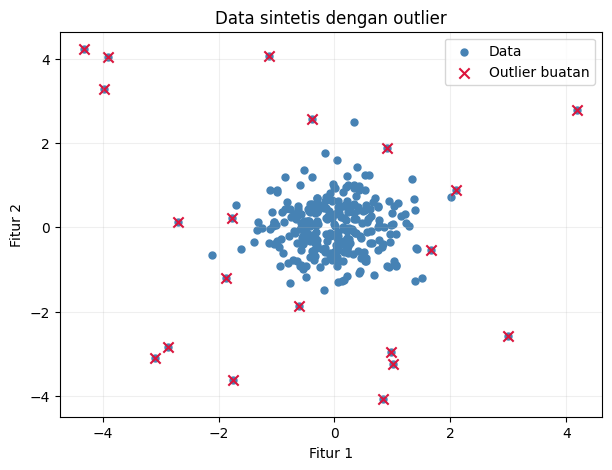

Jumlah data: 300 | outlier buatan: 20


In [2]:
from sklearn.datasets import make_blobs
from sklearn.neighbors import LocalOutlierFactor

rng = np.random.RandomState(42)
X_normal, _ = make_blobs(n_samples=280, centers=[[0, 0]], cluster_std=0.65, random_state=42)
X_outliers = rng.uniform(low=-4.5, high=4.5, size=(20, 2))
X = np.vstack([X_normal, X_outliers])
y_true = np.r_[np.ones(len(X_normal)), -np.ones(len(X_outliers))]

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c='steelblue', s=25, label='Data')
plt.scatter(X_outliers[:, 0], X_outliers[:, 1], c='crimson', marker='x', s=55, label='Outlier buatan')
plt.title('Data sintetis dengan outlier')
plt.xlabel('Fitur 1'); plt.ylabel('Fitur 2'); plt.legend(); plt.grid(alpha=.2)
plt.show()
print('Jumlah data:', len(X), '| outlier buatan:', len(X_outliers))

**Interpretasi.** Sebagian besar titik membentuk satu kelompok padat, sedangkan beberapa titik berada jauh dari kelompok. Karena dataset ini memiliki label kebenaran yang kita buat sendiri, hasil deteksi nantinya dapat dibandingkan dengan label tersebut. Pada data nyata, label anomali sering tidak tersedia.

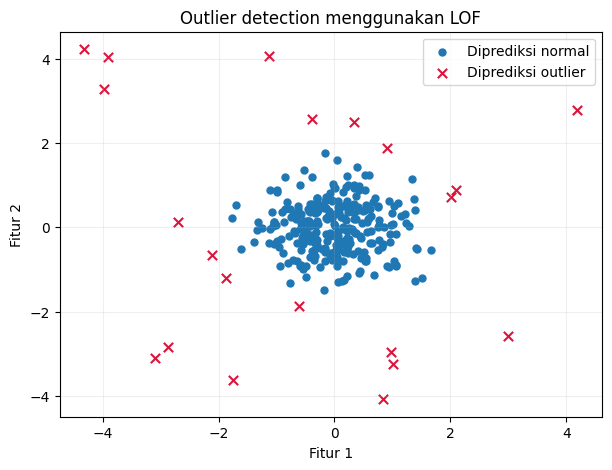

Prediksi normal: 279
Prediksi outlier: 21


In [3]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.07)
y_pred_lof = lof.fit_predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(X[y_pred_lof == 1, 0], X[y_pred_lof == 1, 1], s=25, label='Diprediksi normal')
plt.scatter(X[y_pred_lof == -1, 0], X[y_pred_lof == -1, 1], c='crimson', marker='x', s=45, label='Diprediksi outlier')
plt.title('Outlier detection menggunakan LOF')
plt.xlabel('Fitur 1'); plt.ylabel('Fitur 2'); plt.legend(); plt.grid(alpha=.2)
plt.show()
print('Prediksi normal:', np.sum(y_pred_lof == 1))
print('Prediksi outlier:', np.sum(y_pred_lof == -1))

### Hands-on exercise
1. Ubah `contamination` dari `0.07` menjadi `0.03` dan `0.12`. Bagaimana jumlah titik yang ditandai berubah?
2. Coba dataset dengan dua kelompok normal yang terpisah. Apakah semua titik di antara kelompok akan dianggap anomali?
3. Diskusikan mengapa deteksi anomali perlu mempertimbangkan konteks aplikasi.

## 2. Understanding Isolation Forest

### Ringkasan
`IsolationForest` mengisolasi observasi melalui pemisahan acak. Titik yang lebih mudah diisolasi—biasanya karena berbeda dari mayoritas—cenderung memiliki skor anomali lebih tinggi. Algoritma ini relatif efisien dan dapat digunakan pada banyak fitur.

Parameter penting:
- `n_estimators`: jumlah pohon; lebih banyak pohon dapat menstabilkan hasil dengan biaya komputasi tambahan.
- `contamination`: perkiraan proporsi outlier yang digunakan untuk menentukan ambang prediksi.
- `random_state`: membuat contoh dapat direproduksi.
- `decision_function()`: skor yang lebih rendah menunjukkan observasi lebih abnormal.

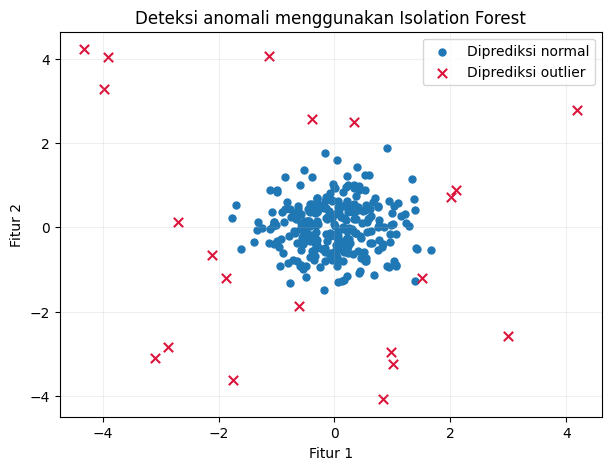

Jumlah outlier terdeteksi: 21
Skor decision_function (5 data pertama): [0.186 0.182 0.171 0.183 0.127]


In [4]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=200, contamination=0.07, random_state=42)
y_pred_iso = iso.fit_predict(X)
scores_iso = iso.decision_function(X)

plt.figure(figsize=(7, 5))
plt.scatter(X[y_pred_iso == 1, 0], X[y_pred_iso == 1, 1], s=25, label='Diprediksi normal')
plt.scatter(X[y_pred_iso == -1, 0], X[y_pred_iso == -1, 1], c='crimson', marker='x', s=45, label='Diprediksi outlier')
plt.title('Deteksi anomali menggunakan Isolation Forest')
plt.xlabel('Fitur 1'); plt.ylabel('Fitur 2'); plt.legend(); plt.grid(alpha=.2)
plt.show()
print('Jumlah outlier terdeteksi:', np.sum(y_pred_iso == -1))
print('Skor decision_function (5 data pertama):', np.round(scores_iso[:5], 3))

**Interpretasi.** Prediksi `-1` menandai observasi yang dianggap anomali. `contamination` bukan cara untuk menjamin jumlah anomali benar; ia membantu menetapkan ambang dan harus dipilih berdasarkan pengetahuan domain atau proses validasi. Isolation Forest tidak memerlukan asumsi bahwa semua data normal membentuk satu kelompok bulat.

### Praktik baik
- Uji beberapa nilai `contamination`, bukan hanya satu nilai default.
- Periksa kembali observasi berisiko tinggi sebelum menghapusnya.
- Walaupun Isolation Forest relatif tidak sensitif terhadap skala dibandingkan metode berbasis jarak, penskalaan tetap dapat membantu saat fitur memiliki rentang yang sangat berbeda.
- Untuk data yang terus berubah, pantau distribusi fitur dan evaluasi ulang model secara berkala.

In [5]:
contamination_values = [0.03, 0.07, 0.12]
rows = []
for cont in contamination_values:
    model = IsolationForest(contamination=cont, random_state=42, n_estimators=150)
    pred = model.fit_predict(X)
    rows.append({'contamination': cont, 'jumlah_outlier': int(np.sum(pred == -1))})

pd.DataFrame(rows)

,contamination,jumlah_outlier
0,0.03,9
1,0.07,21
2,0.12,36


### Hands-on exercise
Bandingkan `n_estimators=50`, `100`, dan `300` dengan `random_state` tetap. Amati kestabilan prediksi dan waktu eksekusi. Lalu ubah `random_state` untuk melihat apakah ada titik yang statusnya berubah.

## 3. One-Class SVM for Novelty Detection

### Ringkasan
`OneClassSVM` mempelajari batas yang mencakup sebagian besar data pelatihan normal. Setelah dilatih, model dapat menandai sampel baru yang berada di luar pola tersebut. Model ini dapat membentuk batas nonlinier menggunakan kernel seperti RBF, tetapi sensitif terhadap skala fitur.

Parameter utama:
- `kernel`: jenis kernel; `rbf` umum untuk pola nonlinier.
- `gamma`: seberapa jauh pengaruh setiap sampel pelatihan.
- `nu`: batas atas fraksi kesalahan pelatihan dan batas bawah fraksi support vectors.

Untuk novelty detection, **latih hanya dengan data normal**, lalu prediksi data baru.

In [6]:
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

# Pisahkan data normal untuk training dan campurkan anomali pada test
rng = np.random.RandomState(7)
X_train, _ = make_blobs(n_samples=240, centers=[[0, 0]], cluster_std=0.55, random_state=7)
X_test_normal, _ = make_blobs(n_samples=100, centers=[[0, 0]], cluster_std=0.55, random_state=19)
X_test_novel = rng.uniform(-4, 4, size=(25, 2))
X_test = np.vstack([X_test_normal, X_test_novel])
y_test_true = np.r_[np.ones(len(X_test_normal)), -np.ones(len(X_test_novel))]

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

ocsvm = OneClassSVM(kernel='rbf', gamma='scale', nu=0.08)
ocsvm.fit(X_train_scaled)
y_pred_ocsvm = ocsvm.predict(X_test_scaled)
print('Prediksi normal:', np.sum(y_pred_ocsvm == 1))
print('Prediksi novelty:', np.sum(y_pred_ocsvm == -1))

Prediksi normal: 93
Prediksi novelty: 32


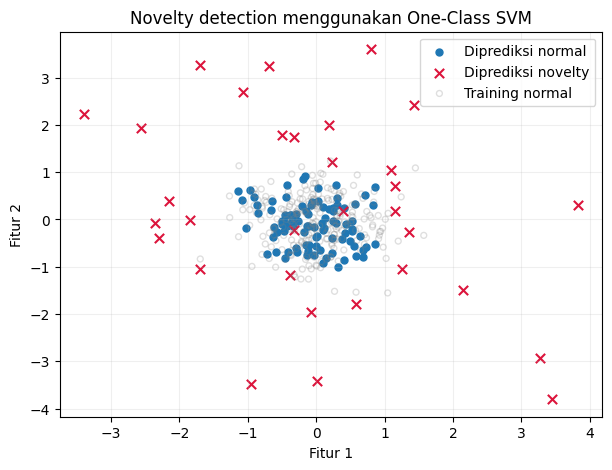

In [7]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test[y_pred_ocsvm == 1, 0], X_test[y_pred_ocsvm == 1, 1], s=25, label='Diprediksi normal')
plt.scatter(X_test[y_pred_ocsvm == -1, 0], X_test[y_pred_ocsvm == -1, 1], c='crimson', marker='x', s=45, label='Diprediksi novelty')
plt.scatter(X_train[:, 0], X_train[:, 1], facecolors='none', edgecolors='gray', s=18, alpha=.25, label='Training normal')
plt.title('Novelty detection menggunakan One-Class SVM')
plt.xlabel('Fitur 1'); plt.ylabel('Fitur 2'); plt.legend(); plt.grid(alpha=.2)
plt.show()

**Interpretasi.** Berbeda dari contoh LOF sebelumnya, `OneClassSVM` dilatih hanya pada `X_train` yang berisi data normal. Ketika `predict()` digunakan pada `X_test`, nilai `-1` berarti data baru berada di luar pola normal yang dipelajari. Penskalaan dilakukan dengan `StandardScaler` yang hanya di-*fit* pada training data agar informasi test tidak bocor ke proses pelatihan.

### Kapan cocok?
- Cocok ketika tersedia banyak contoh kondisi normal dan sedikit atau tidak ada label anomali.
- Dapat memodelkan batas nonlinier, tetapi tuning `nu` dan `gamma` dapat berpengaruh besar.
- Pada dataset sangat besar, biaya komputasi SVM dapat menjadi pertimbangan.

### Hands-on exercise
Coba `nu=0.03`, `0.08`, dan `0.15`. Amati jumlah data test yang dianggap novelty. Kemudian bandingkan `kernel='linear'` dengan `kernel='rbf'` dan jelaskan perbedaan batas keputusan yang dihasilkan.

## 4. Detecting Outliers with LOF

### Ringkasan
`LocalOutlierFactor` (*LOF*) adalah metode berbasis kepadatan lokal. Ia membandingkan kepadatan di sekitar suatu titik dengan kepadatan tetangganya. Titik yang berada di lingkungan jauh lebih renggang daripada tetangganya berpotensi menjadi outlier.

- `n_neighbors`: jumlah tetangga yang digunakan untuk mengukur kepadatan lokal.
- `contamination`: perkiraan proporsi outlier untuk ambang prediksi.
- Untuk deteksi outlier pada data pelatihan, gunakan `fit_predict(X)`.
- Untuk novelty detection pada data baru, aktifkan `novelty=True`, lalu gunakan `fit(X_train)` dan `predict(X_new)`. Jangan gunakan `predict` pada data training yang sama dengan cara kerja novelty mode.

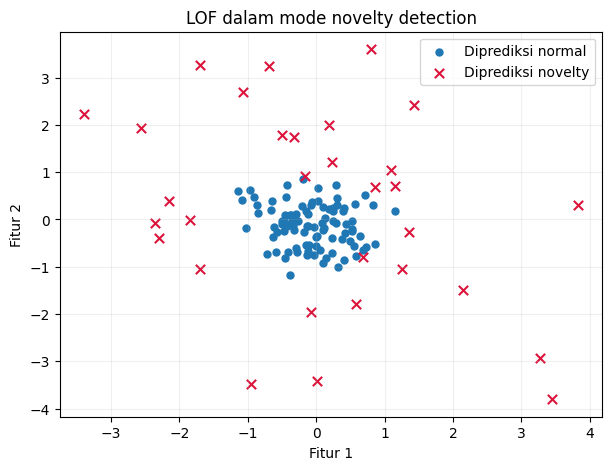

Novelty yang ditandai: 31


In [8]:
# LOF untuk novelty detection pada data baru
lof_novelty = LocalOutlierFactor(n_neighbors=20, contamination=0.08, novelty=True)
lof_novelty.fit(X_train_scaled)
y_pred_lof_new = lof_novelty.predict(X_test_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X_test[y_pred_lof_new == 1, 0], X_test[y_pred_lof_new == 1, 1], s=25, label='Diprediksi normal')
plt.scatter(X_test[y_pred_lof_new == -1, 0], X_test[y_pred_lof_new == -1, 1], c='crimson', marker='x', s=45, label='Diprediksi novelty')
plt.title('LOF dalam mode novelty detection')
plt.xlabel('Fitur 1'); plt.ylabel('Fitur 2'); plt.legend(); plt.grid(alpha=.2)
plt.show()
print('Novelty yang ditandai:', np.sum(y_pred_lof_new == -1))

**Interpretasi.** LOF dapat berguna ketika anomali ditentukan oleh lingkungan lokal, bukan hanya jarak global dari pusat data. Akan tetapi, hasilnya bergantung pada `n_neighbors` dan bentuk distribusi. Sebuah titik bisa normal di area berkepadatan rendah jika tetangganya juga memiliki kepadatan serupa.

### Hands-on exercise
Ubah `n_neighbors` menjadi `5`, `20`, dan `40`. Bandingkan titik yang ditandai oleh LOF dengan Isolation Forest. Perhatikan bahwa kedua algoritma memakai prinsip yang berbeda, sehingga prediksi tidak harus sama.

## 5. Evaluating Outlier Detection Models

### Ringkasan
Evaluasi lebih sulit daripada klasifikasi biasa karena label anomali sering langka atau tidak tersedia. Jika label acuan ada, kita dapat membandingkan prediksi dengan label tersebut menggunakan precision, recall, F1, dan confusion matrix. Jika label tidak ada, gunakan penilaian ahli, pemeriksaan kasus, atau kestabilan hasil sebagai bagian dari evaluasi.

Dalam contoh sintetis berikut, `1` berarti normal dan `-1` berarti outlier agar cocok dengan konvensi prediksi estimator di atas.

In [9]:
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score, f1_score

# Evaluasi Isolation Forest pada dataset sintetis berlabel
print('Confusion matrix (baris=true, kolom=prediksi; urutan label [1, -1]):')
print(confusion_matrix(y_true, y_pred_iso, labels=[1, -1]))
print(f"Precision outlier: {precision_score(y_true, y_pred_iso, pos_label=-1):.3f}")
print(f"Recall outlier:    {recall_score(y_true, y_pred_iso, pos_label=-1):.3f}")
print(f"F1 outlier:        {f1_score(y_true, y_pred_iso, pos_label=-1):.3f}")

Confusion matrix (baris=true, kolom=prediksi; urutan label [1, -1]):
[[276   4]
 [  3  17]]
Precision outlier: 0.810
Recall outlier:    0.850
F1 outlier:        0.829


**Cara membaca metrik:**
- **Precision anomali**: dari semua titik yang ditandai sebagai anomali, berapa yang benar-benar anomali. Precision rendah berarti banyak *false positive*.
- **Recall anomali**: dari seluruh anomali sebenarnya, berapa yang berhasil ditemukan. Recall rendah berarti banyak *false negative*.
- **F1-score**: rata-rata harmonik precision dan recall.

Pada aplikasi medis atau keselamatan, biaya false negative mungkin sangat tinggi. Pada sistem investigasi yang setiap alarm-nya mahal untuk ditindaklanjuti, false positive juga perlu dikendalikan. Pilihan metrik harus mengikuti konsekuensi aplikasi.

In [10]:
# Bandingkan beberapa detektor pada label sintetis yang sama
predictions = {
    'LOF': y_pred_lof,
    'Isolation Forest': y_pred_iso,
}
comparison = []
for name, pred in predictions.items():
    comparison.append({
        'Model': name,
        'Precision outlier': precision_score(y_true, pred, pos_label=-1, zero_division=0),
        'Recall outlier': recall_score(y_true, pred, pos_label=-1, zero_division=0),
        'F1 outlier': f1_score(y_true, pred, pos_label=-1, zero_division=0),
        'Jumlah ditandai': int(np.sum(pred == -1)),
    })
pd.DataFrame(comparison).round(3)

,Model,Precision outlier,Recall outlier,F1 outlier,Jumlah ditandai
0,LOF,0.857,0.90,0.878,21
1,Isolation Forest,0.810,0.85,0.829,21


> **Penting:** skor pada data sintetis ini bukan bukti bahwa satu algoritma selalu lebih unggul. Hasil bergantung pada bentuk data, proporsi anomali, parameter, serta apakah label buatan benar-benar mewakili kondisi operasional. Jika label tersedia, pertimbangkan validasi pada data terpisah.

## 6. Handling Detected Outliers

### Ringkasan
Menemukan outlier tidak otomatis berarti data harus dihapus. Penanganan bergantung pada penyebab dan tujuan analisis.

1. **Validasi data:** periksa sensor, format, satuan, duplikasi, atau kesalahan input.
2. **Investigasi:** pastikan apakah anomali merupakan kejadian nyata yang penting.
3. **Perbaiki atau keluarkan:** hanya jika ada alasan yang dapat dipertanggungjawabkan, misalnya kesalahan pengukuran yang terkonfirmasi.
4. **Transformasi atau metode robust:** untuk sebagian masalah, transformasi fitur atau model yang tahan terhadap nilai ekstrem dapat lebih tepat.
5. **Pantau:** pada sistem produksi, perubahan pola anomali dapat mengindikasikan perubahan proses atau *concept drift*.

In [11]:
# Contoh alur: tandai dahulu, jangan langsung menghapus
results = pd.DataFrame(X, columns=['fitur_1', 'fitur_2'])
results['label_acuan'] = y_true
results['prediksi_iso'] = y_pred_iso
results['skor_iso'] = scores_iso
results['status_review'] = np.where(results['prediksi_iso'] == -1, 'Perlu ditinjau', 'Belum ditandai')

print(results['status_review'].value_counts())
results.loc[results['prediksi_iso'] == -1].head(10)

status_review
Belum ditandai    279
Perlu ditinjau     21
Name: count, dtype: int64


,fitur_1,fitur_2,label_acuan,prediksi_iso,skor_iso,status_review
124,0.334781,2.504275,1.0,-1,-0.030158,Perlu ditinjau
227,2.001273,0.727724,1.0,-1,-0.036823,Perlu ditinjau
250,1.504528,-1.213722,1.0,-1,-0.004100,Perlu ditinjau
277,-2.106824,-0.665852,1.0,-1,-0.028313,Perlu ditinjau
280,-1.129139,4.056429,-1.0,-1,-0.148903,Perlu ditinjau
281,2.087945,0.887926,-1.0,-1,-0.057009,Perlu ditinjau
282,-3.095832,-3.096049,-1.0,-1,-0.162207,Perlu ditinjau
283,-3.977247,3.295585,-1.0,-1,-0.181977,Perlu ditinjau
285,-4.314740,4.229189,-1.0,-1,-0.213490,Perlu ditinjau
286,2.991984,-2.588948,-1.0,-1,-0.182729,Perlu ditinjau


**Mengapa ditandai dulu?** Baris yang dicurigai dapat diserahkan untuk pemeriksaan sebelum keputusan dibuat. Menghapus semua prediksi `-1` tanpa verifikasi berisiko membuang kejadian langka yang sah atau informasi yang justru penting untuk model.

Jika memang diperlukan untuk analisis tertentu, bandingkan hasil dengan dan tanpa observasi yang sudah diverifikasi sebagai kesalahan. Catat aturan penghapusan agar proses dapat diaudit dan diulang.

## 7. Choosing the Right Detection Technique

### Ringkasan perbandingan

| Teknik | Prinsip | Kelebihan | Perhatian |
|:--|:--|:--|:--|
| **Isolation Forest** | Mengisolasi titik melalui pemisahan acak | Efisien untuk banyak data/fitur | Perlu ambang/`contamination` yang masuk akal |
| **One-Class SVM** | Mempelajari batas data normal | Batas nonlinier dengan kernel | Sensitif terhadap scaling dan parameter; mahal pada data besar |
| **Local Outlier Factor (LOF)** | Membandingkan kepadatan lokal | Dapat menemukan anomali lokal | Bergantung pada `n_neighbors`; perilaku berbeda pada novelty mode |

### Panduan praktis
- Mulai dengan memahami data, skala fitur, dan kemungkinan sumber anomali.
- Gunakan Isolation Forest sebagai kandidat awal yang efisien.
- Pertimbangkan LOF jika kepadatan lokal penting dan struktur data tidak seragam.
- Pertimbangkan One-Class SVM jika data normal tersedia untuk pelatihan dan batas nonlinier dibutuhkan.
- Evaluasi dengan label jika tersedia, dan libatkan pemeriksaan domain jika tidak.
- Jangan memilih model hanya berdasarkan banyaknya titik yang ditandai.

In [12]:
# Ringkasan kuantitatif: berapa banyak titik yang ditandai setiap metode?
summary = pd.DataFrame([
    {'Metode': 'LOF (outlier detection)', 'Jumlah ditandai': int(np.sum(y_pred_lof == -1))},
    {'Metode': 'Isolation Forest', 'Jumlah ditandai': int(np.sum(y_pred_iso == -1))},
    {'Metode': 'One-Class SVM (novelty)', 'Jumlah ditandai pada test': int(np.sum(y_pred_ocsvm == -1))},
    {'Metode': 'LOF (novelty)', 'Jumlah ditandai pada test': int(np.sum(y_pred_lof_new == -1))},
])
summary.fillna('—')

,Metode,Jumlah ditandai,Jumlah ditandai pada test
0,LOF (outlier detection),21.0,—
1,Isolation Forest,21.0,—
2,One-Class SVM (novelty),—,32.0
3,LOF (novelty),—,31.0


### Kesimpulan
Deteksi outlier dan novelty membantu mengidentifikasi data yang menyimpang dari pola umum, tetapi tidak ada satu algoritma yang cocok untuk semua distribusi. Isolation Forest menggunakan isolasi acak, One-Class SVM mempelajari batas data normal, dan LOF membandingkan kepadatan lokal. Pilihan yang baik mempertimbangkan konteks, skala data, ketersediaan label, biaya kesalahan, dan kebutuhan operasional.

### Latihan akhir
1. Jalankan kembali notebook dengan `contamination` berbeda dan bandingkan jumlah anomali.
2. Buat data normal dengan dua cluster dan tambahkan outlier di dekat salah satu cluster.
3. Bandingkan precision dan recall Isolation Forest serta LOF pada label sintetis.
4. Jelaskan kapan sebaiknya anomali diperiksa, dipertahankan, diperbaiki, atau dihapus.
5. Jelaskan perbedaan prosedur `fit_predict(X)` pada LOF outlier detection dan `fit(X_train)` lalu `predict(X_new)` pada novelty detection.